#1.Kullanılan Kütüphaneler

###Bu çalışmada Python programlama dili ile Pandas, NumPy ve Matplotlib kütüphaneleri kullanılmıştır.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True

#2.Veri Setlerinin İncelenmesi

###Excel dosyasında bulunan öğrenci, günlük sınav ve günlük değerlendirme tabloları incelenmiştir.

In [ ]:
dosya_yolu = "degerlendirme_veri.xlsx"

ogrenciler = pd.read_excel(dosya_yolu, sheet_name="Ogrenciler")
sinav = pd.read_excel(dosya_yolu, sheet_name="Gunluk_Sinav")
degerlendirme = pd.read_excel(dosya_yolu, sheet_name="Gunluk_Degerlendirme")

sinav["Tarih"] = pd.to_datetime(sinav["Tarih"])
degerlendirme["Tarih"] = pd.to_datetime(degerlendirme["Tarih"])

print("Öğrenci tablosu:", ogrenciler.shape)
print("Sınav tablosu:", sinav.shape)
print("Değerlendirme tablosu:", degerlendirme.shape)

display(ogrenciler.head())
display(sinav.head())
display(degerlendirme.head())

Öğrenci tablosu: (50, 3)
Sınav tablosu: (650, 3)
Değerlendirme tablosu: (650, 3)


,No,Ad Soyad,Grup
0,1,Ahmet Yıldırım,A
1,2,Mehmet Demir,B
2,3,Ayşe Kaya,C
3,4,Fatma Şahin,A
4,5,Hasan Arslan,B


,Tarih,No,Not
0,2022-10-10,1,50.0
1,2022-10-10,2,100.0
2,2022-10-10,3,100.0
3,2022-10-10,4,100.0
4,2022-10-10,5,100.0


,Tarih,No,Puan
0,2022-10-10,1,3
1,2022-10-10,2,6
2,2022-10-10,3,6
3,2022-10-10,4,6
4,2022-10-10,5,6


#3.Veri Ön İşleme
###Veri setleri kontrol edilmiş, eksik değerler ve tekrar eden kayıtlar incelenmiştir.

In [ ]:
print("Öğrenci tablosu eksik değer sayıları")
display(ogrenciler.isnull().sum())

print("Sınav tablosu eksik değer sayıları")
display(sinav.isnull().sum())

print("Değerlendirme tablosu eksik değer sayıları")
display(degerlendirme.isnull().sum())

print("Öğrenci numarası tekrarları:", ogrenciler["No"].duplicated().sum())
print("Sınav kayıtlarında tekrar:", sinav.duplicated(subset=["Tarih", "No"]).sum())
print("Değerlendirme kayıtlarında tekrar:", degerlendirme.duplicated(subset=["Tarih", "No"]).sum())

print("Sınav puanı aralığı:", sinav["Not"].min(), "-", sinav["Not"].max())
print("Değerlendirme puanı aralığı:", degerlendirme["Puan"].min(), "-", degerlendirme["Puan"].max())
print("Gruplar:", sorted(ogrenciler["Grup"].dropna().unique()))
print("Tarih aralığı:", sinav["Tarih"].min().date(), "-", sinav["Tarih"].max().date())

Öğrenci tablosu eksik değer sayıları


,0
No,0
Ad Soyad,0
Grup,0


Sınav tablosu eksik değer sayıları


,0
Tarih,0
No,0
Not,0


Değerlendirme tablosu eksik değer sayıları


,0
Tarih,0
No,0
Puan,0


Öğrenci numarası tekrarları: 0
Sınav kayıtlarında tekrar: 0
Değerlendirme kayıtlarında tekrar: 0
Sınav puanı aralığı: 0.0 - 100.0
Değerlendirme puanı aralığı: 0 - 9
Gruplar: ['A', 'B', 'C']
Tarih aralığı: 2022-10-10 - 2022-10-22


#4.Öğrencilerin Gruplara Dağılımı

###Öğrenciler A, B ve C gruplarına göre gruplandırılmış, her gruptaki öğrenci sayısı hesaplanarak sütun grafiği ile görselleştirilmiştir.

,Öğrenci Sayısı
Grup,
A,17
B,17
C,16


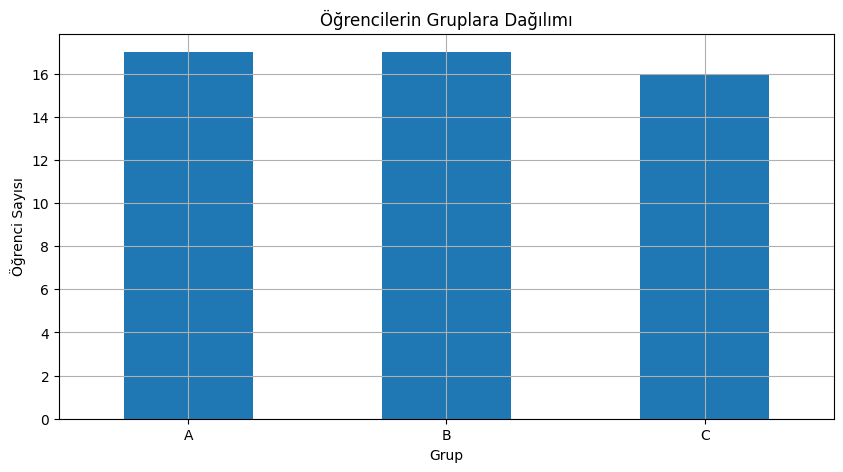

In [6]:
grup_dagilimi = (
    ogrenciler.groupby("Grup")["No"]
    .nunique()
    .reindex(["A", "B", "C"])
    .fillna(0)
    .astype(int)
)

display(grup_dagilimi.rename("Öğrenci Sayısı").to_frame())

grup_dagilimi.plot(kind="bar", title="Öğrencilerin Gruplara Dağılımı")
plt.xlabel("Grup")
plt.ylabel("Öğrenci Sayısı")
plt.xticks(rotation=0)
plt.show()

# 5. Verilerin Birleştirilmesi

Günlük sınav ve değerlendirme verileri tarih ve öğrenci numarası kullanılarak birleştirilmiştir. Öğrenci adı ve grup bilgileri de eklenerek analiz için tek bir veri tablosu oluşturulmuştur.

In [7]:
veri = pd.merge(
    sinav,
    degerlendirme,
    on=["Tarih", "No"],
    how="inner",
    validate="one_to_one"
)

veri = pd.merge(
    veri,
    ogrenciler[["No", "Ad Soyad", "Grup"]],
    on="No",
    how="left",
    validate="many_to_one"
)

veri = veri[["Tarih", "No", "Ad Soyad", "Grup", "Not", "Puan"]]
veri = veri.sort_values(["Tarih", "No"]).reset_index(drop=True)

print("Birleştirilmiş veri boyutu:", veri.shape)
display(veri.head(10))

Birleştirilmiş veri boyutu: (650, 6)


,Tarih,No,Ad Soyad,Grup,Not,Puan
0,2022-10-10,1,Ahmet Yıldırım,A,50.00,3
1,2022-10-10,2,Mehmet Demir,B,100.00,6
2,2022-10-10,3,Ayşe Kaya,C,100.00,6
3,2022-10-10,4,Fatma Şahin,A,100.00,6
4,2022-10-10,5,Hasan Arslan,B,100.00,6
5,2022-10-10,6,Hüseyin Yalçın,C,100.00,6
6,2022-10-10,7,Zeynep Aydın,A,100.00,6
7,2022-10-10,8,Emre Korkmaz,B,100.00,6
8,2022-10-10,9,Elif Çetin,C,0.00,0
9,2022-10-10,10,Murat Koç,A,16.67,1


#6.Min-Max normalizasyonu ve başarı puanı
Rehberde verilen formüle göre sınav notu ve değerlendirme puanı ayrı ayrı 0–1 aralığına dönüştürülür. Normalizasyon, veri setinin tamamındaki minimum ve maksimum değerler kullanılarak yapılır.

Başarı puanı:
- Normalize sınav notu ağırlığı: %70
- Normalize değerlendirme puanı ağırlığı: %30

In [8]:
sinav_min = veri["Not"].min()
sinav_max = veri["Not"].max()
puan_min = veri["Puan"].min()
puan_max = veri["Puan"].max()

if sinav_max == sinav_min or puan_max == puan_min:
    raise ValueError("Normalizasyon için minimum ve maksimum değerler birbirinden farklı olmalıdır.")

veri["Normalize_Sinav"] = (veri["Not"] - sinav_min) / (sinav_max - sinav_min)
veri["Normalize_Degerlendirme"] = (veri["Puan"] - puan_min) / (puan_max - puan_min)

veri["Basari_Puani"] = (
    veri["Normalize_Sinav"] * 0.7
    + veri["Normalize_Degerlendirme"] * 0.3
)

display(veri.head(10))
print("Normalize sınav aralığı:",
      veri["Normalize_Sinav"].min(), "-", veri["Normalize_Sinav"].max())
print("Normalize değerlendirme aralığı:",
      veri["Normalize_Degerlendirme"].min(), "-", veri["Normalize_Degerlendirme"].max())

,Tarih,No,Ad Soyad,Grup,Not,Puan,Normalize_Sinav,Normalize_Degerlendirme,Basari_Puani
0,2022-10-10,1,Ahmet Yıldırım,A,50.00,3,0.5000,0.333333,0.450000
1,2022-10-10,2,Mehmet Demir,B,100.00,6,1.0000,0.666667,0.900000
2,2022-10-10,3,Ayşe Kaya,C,100.00,6,1.0000,0.666667,0.900000
3,2022-10-10,4,Fatma Şahin,A,100.00,6,1.0000,0.666667,0.900000
4,2022-10-10,5,Hasan Arslan,B,100.00,6,1.0000,0.666667,0.900000
5,2022-10-10,6,Hüseyin Yalçın,C,100.00,6,1.0000,0.666667,0.900000
6,2022-10-10,7,Zeynep Aydın,A,100.00,6,1.0000,0.666667,0.900000
7,2022-10-10,8,Emre Korkmaz,B,100.00,6,1.0000,0.666667,0.900000
8,2022-10-10,9,Elif Çetin,C,0.00,0,0.0000,0.000000,0.000000
9,2022-10-10,10,Murat Koç,A,16.67,1,0.1667,0.111111,0.150023


Normalize sınav aralığı: 0.0 - 1.0
Normalize değerlendirme aralığı: 0.0 - 1.0


#7. Başarı puanına göre en başarılı 10 öğrenci

##Her öğrencinin bütün tarihlerdeki başarı puanlarının ortalaması alınır. Öğrenciler bu ortalamaya göre büyükten küçüğe sıralanır.

,No,Ad Soyad,Grup,Ortalama_Basari,Ortalama_Sinav,Ortalama_Degerlendirme,Sinav_Kaydi
3,4,Fatma Şahin,A,0.894872,100.0,5.846154,13
2,3,Ayşe Kaya,C,0.894872,100.0,5.846154,13
16,17,Barış Kurt,B,0.894872,100.0,5.846154,13
36,37,Volkan Ersoy,A,0.894872,100.0,5.846154,13
41,42,Levent Güney,C,0.894872,100.0,5.846154,13
43,44,Metin Baştürk,B,0.894872,100.0,5.846154,13
48,49,Doğan Güler,A,0.894872,100.0,5.846154,13
39,40,Ahmetcan Karakaya,A,0.894872,100.0,5.846154,13
26,27,Kadir Kılıç,C,0.894872,100.0,5.846154,13
22,23,Cemal Sezer,B,0.894872,100.0,5.846154,13


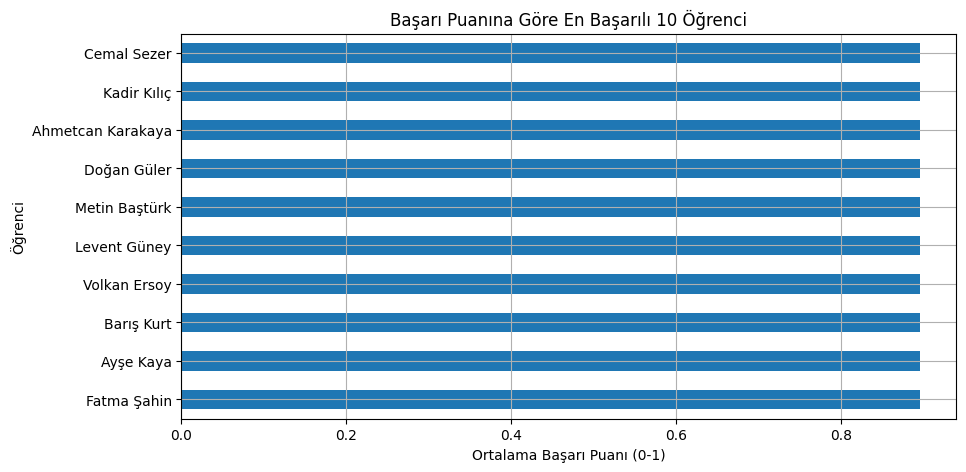

In [9]:
ogrenci_basari = (
    veri.groupby(["No", "Ad Soyad", "Grup"], as_index=False)
    .agg(
        Ortalama_Basari=("Basari_Puani", "mean"),
        Ortalama_Sinav=("Not", "mean"),
        Ortalama_Degerlendirme=("Puan", "mean"),
        Sinav_Kaydi=("Not", "count")
    )
    .sort_values("Ortalama_Basari", ascending=False)
)

ilk_10_ogrenci = ogrenci_basari.head(10)
display(ilk_10_ogrenci)

ilk_10_ogrenci.sort_values("Ortalama_Basari").plot(
    x="Ad Soyad", y="Ortalama_Basari", kind="barh",
    title="Başarı Puanına Göre En Başarılı 10 Öğrenci",
    legend=False
)
plt.xlabel("Ortalama Başarı Puanı (0-1)")
plt.ylabel("Öğrenci")
plt.show()

#8. Başarı puanına göre en başarılı grup

##Her grubun tüm tarihlerdeki tüm öğrenci kayıtlarının ortalama başarı puanı hesaplanır. Böylece gruplar aynı başarı ölçütü üzerinden karşılaştırılır.

,Grup,Ortalama_Basari,Ortalama_Sinav,Ortalama_Degerlendirme,Kayit_Sayisi
1,B,0.674344,75.218688,4.434389,221
0,A,0.654059,73.031946,4.285068,221
2,C,0.638168,71.272212,4.177885,208


En başarılı grup: B (ortalama başarı puanı: 0.6743)


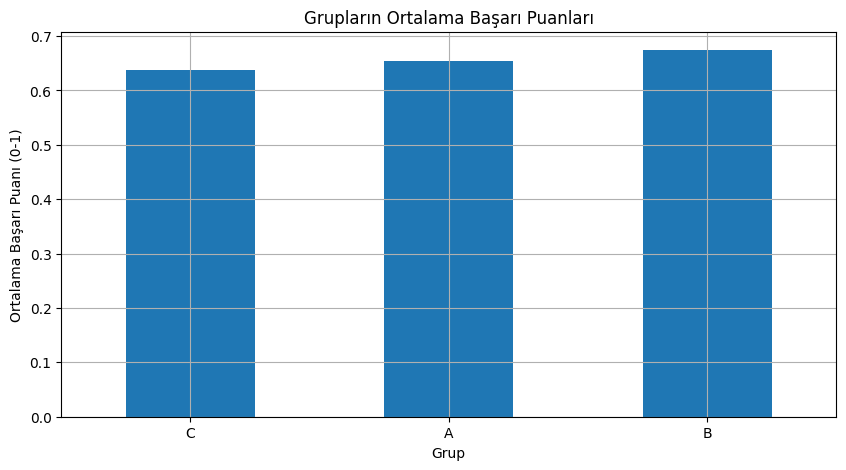

In [10]:
grup_basari = (
    veri.groupby("Grup", as_index=False)
    .agg(
        Ortalama_Basari=("Basari_Puani", "mean"),
        Ortalama_Sinav=("Not", "mean"),
        Ortalama_Degerlendirme=("Puan", "mean"),
        Kayit_Sayisi=("Basari_Puani", "count")
    )
    .sort_values("Ortalama_Basari", ascending=False)
)

display(grup_basari)

en_bas_ar = grup_basari.iloc[0]
print(
    f"En başarılı grup: {en_bas_ar['Grup']} "
    f"(ortalama başarı puanı: {en_bas_ar['Ortalama_Basari']:.4f})"
)

grup_basari.sort_values("Ortalama_Basari").plot(
    x="Grup", y="Ortalama_Basari", kind="bar",
    title="Grupların Ortalama Başarı Puanları",
    legend=False
)
plt.xlabel("Grup")
plt.ylabel("Ortalama Başarı Puanı (0-1)")
plt.xticks(rotation=0)
plt.show()

#9. Seçilen tarih aralığında grupların başarı grafiği

##Aşağıdaki başlangıç ve bitiş tarihleri değiştirilerek farklı dönemler incelenebilir. Varsayılan olarak veri setindeki tüm tarih aralığı seçilmiştir.

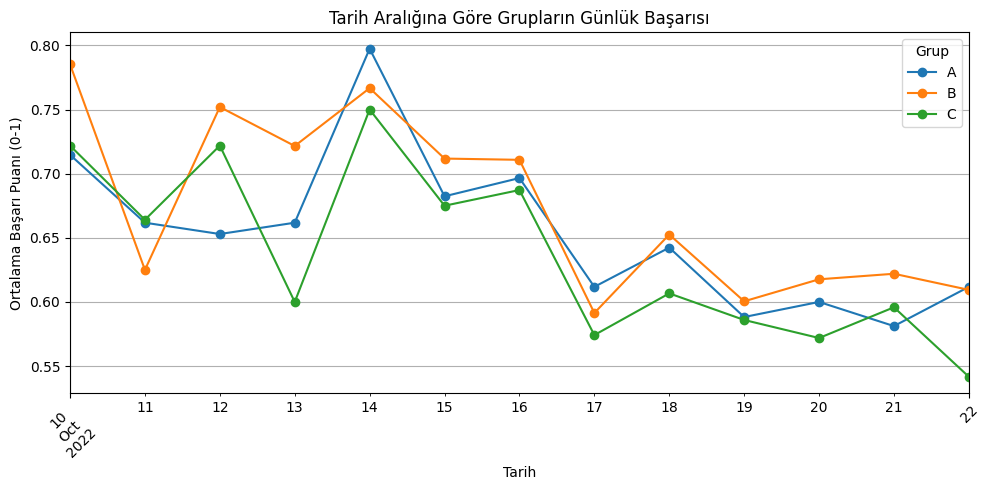

In [11]:
baslangic_tarihi = veri["Tarih"].min()
bitis_tarihi = veri["Tarih"].max()

tarih_araligi_veri = veri[
    (veri["Tarih"] >= pd.to_datetime(baslangic_tarihi))
    & (veri["Tarih"] <= pd.to_datetime(bitis_tarihi))
]

gunluk_grup_basari = (
    tarih_araligi_veri.groupby(["Tarih", "Grup"])["Basari_Puani"]
    .mean()
    .reset_index()
)

grup_grafik = gunluk_grup_basari.pivot(
    index="Tarih", columns="Grup", values="Basari_Puani"
)

grup_grafik.plot(marker="o", title="Tarih Aralığına Göre Grupların Günlük Başarısı")
plt.xlabel("Tarih")
plt.ylabel("Ortalama Başarı Puanı (0-1)")
plt.legend(title="Grup")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#10. Günlük sınav ortalamasının değişimi

##Her tarih için bütün öğrencilerin sınav notlarının ortalaması hesaplanır ve zaman içindeki değişim çizgi grafiğiyle gösterilir.

,Tarih,Gunluk_Sinav_Ortalamasi
0,2022-10-10,82.3332
1,2022-10-11,78.0000
2,2022-10-12,78.6662
3,2022-10-13,73.6666
4,2022-10-14,77.1114
5,2022-10-15,73.9998
6,2022-10-16,72.2500
7,2022-10-17,68.4000
8,2022-10-18,73.2000
9,2022-10-19,71.0000


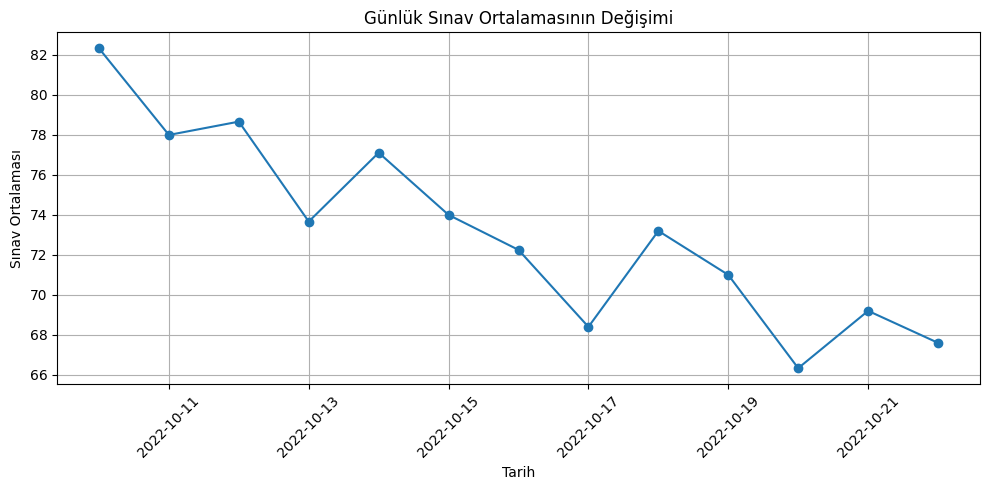

In [12]:
gunluk_sinav_ort = (
    veri.groupby("Tarih")["Not"]
    .mean()
    .reset_index(name="Gunluk_Sinav_Ortalamasi")
)

display(gunluk_sinav_ort)

plt.plot(
    gunluk_sinav_ort["Tarih"],
    gunluk_sinav_ort["Gunluk_Sinav_Ortalamasi"],
    marker="o"
)
plt.title("Günlük Sınav Ortalamasının Değişimi")
plt.xlabel("Tarih")
plt.ylabel("Sınav Ortalaması")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#11. Tanımlayıcı istatistikler

##Sınav notu, değerlendirme puanı ve hesaplanan başarı puanı için gözlem sayısı, ortalama, standart sapma, minimum, medyan, mod ve maksimum değerleri hesaplanır. Ayrıca öğrenci ve grup sayıları özetlenir.

In [13]:
istatistik_kolonlari = ["Not", "Puan", "Basari_Puani"]

tan_tablo = veri[istatistik_kolonlari].agg(
    ["count", "mean", "median", "std", "min", "max"]
).T

mod_degerleri = veri[istatistik_kolonlari].mode().iloc[0]
tan_tablo["Mod"] = mod_degerleri

tan_tablo = tan_tablo[
    ["count", "mean", "median", "Mod", "std", "min", "max"]
]
tan_tablo.columns = [
    "Gözlem Sayısı", "Ortalama", "Medyan", "Mod",
    "Standart Sapma", "Minimum", "Maksimum"
]

display(tan_tablo.round(3))

print("Toplam öğrenci sayısı:", ogrenciler["No"].nunique())
print("Toplam grup sayısı:", ogrenciler["Grup"].nunique())
print("Toplam sınav kaydı:", len(sinav))
print("Toplam değerlendirme kaydı:", len(degerlendirme))

,Gözlem Sayısı,Ortalama,Medyan,Mod,Standart Sapma,Minimum,Maksimum
Not,650.0,73.212,100.000,100.0,39.873,0.0,100.0
Puan,650.0,4.302,5.000,5.0,2.629,0.0,9.0
Basari_Puani,650.0,0.656,0.867,0.0,0.359,0.0,1.0


Toplam öğrenci sayısı: 50
Toplam grup sayısı: 3
Toplam sınav kaydı: 650
Toplam değerlendirme kaydı: 650


#11.1. Sınav notu, değerlendirme ve başarı puanlarının dağılımı

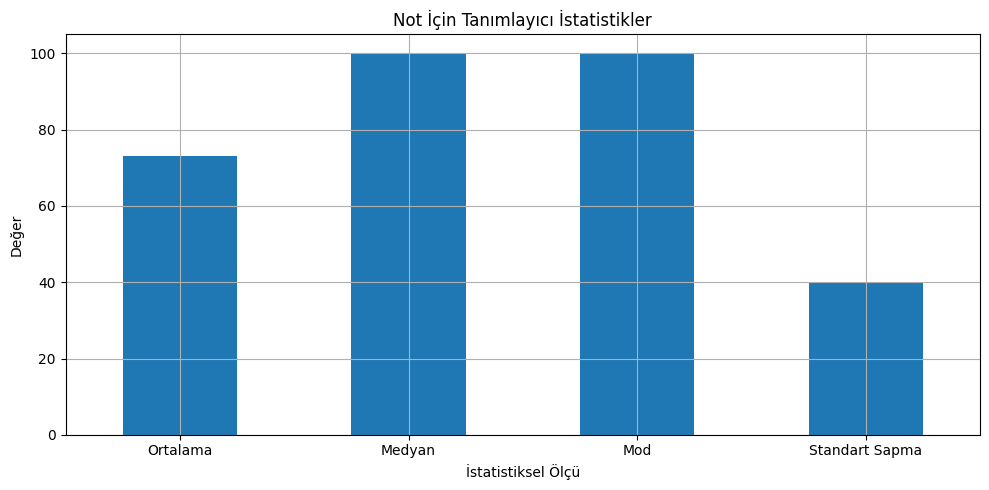

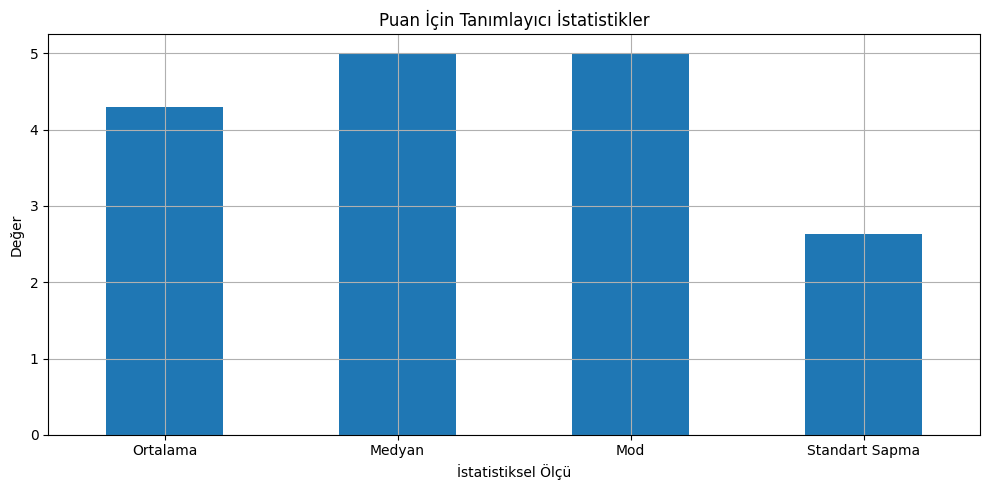

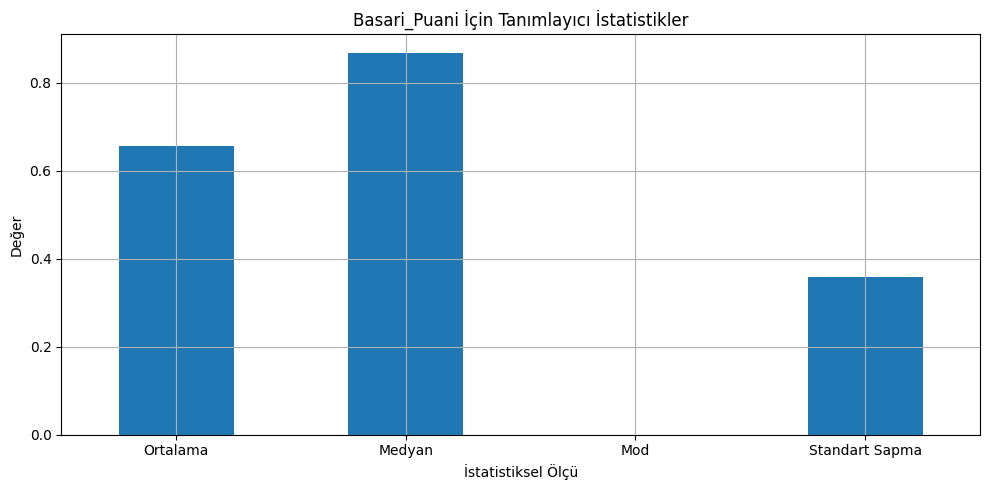

In [14]:
istatistik_gorsel = tan_tablo[["Ortalama", "Medyan", "Mod", "Standart Sapma"]]

for degisken in istatistik_gorsel.index:
    ax = istatistik_gorsel.loc[degisken].plot(
        kind="bar",
        title=f"{degisken} İçin Tanımlayıcı İstatistikler",
        rot=0
    )
    ax.set_xlabel("İstatistiksel Ölçü")
    ax.set_ylabel("Değer")
    plt.tight_layout()
    plt.show()

#11.2. Ortalama, medyan, mod ve standart sapmanın görselleştirilmesi

##Aşağıdaki grafiklerde her değişken için ortalama, medyan, mod ve standart sapma ayrı ayrı gösterilir. Böylece istatistiksel değerler yalnızca tabloda verilmez, grafik üzerinden de karşılaştırılabilir. Standart sapma yayılımı; diğer üç değer ise merkezi eğilimi ifade eder.

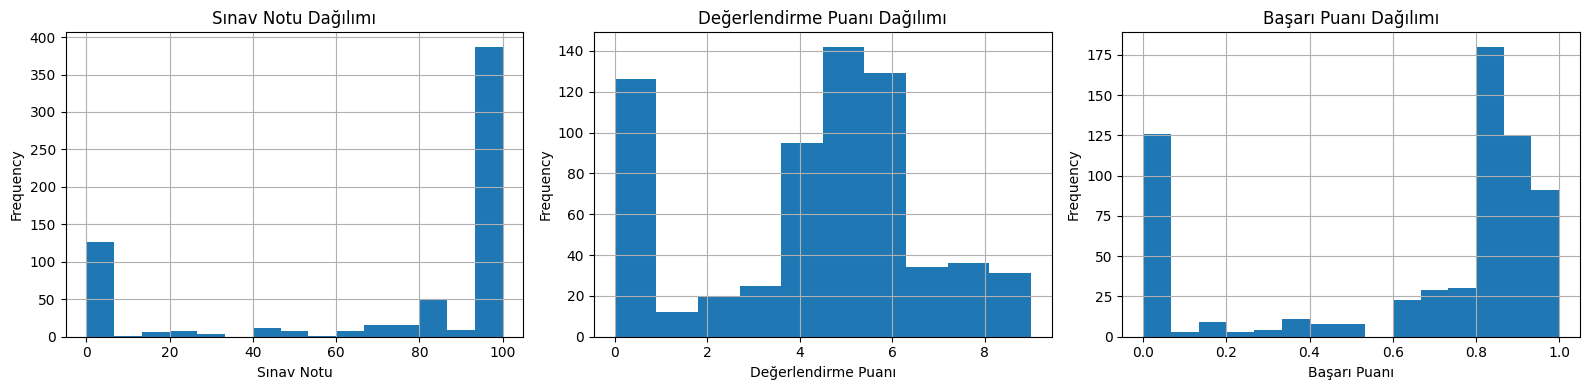

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

veri["Not"].plot(kind="hist", bins=15, ax=axes[0], title="Sınav Notu Dağılımı")
axes[0].set_xlabel("Sınav Notu")

veri["Puan"].plot(kind="hist", bins=10, ax=axes[1], title="Değerlendirme Puanı Dağılımı")
axes[1].set_xlabel("Değerlendirme Puanı")

veri["Basari_Puani"].plot(kind="hist", bins=15, ax=axes[2], title="Başarı Puanı Dağılımı")
axes[2].set_xlabel("Başarı Puanı")

plt.tight_layout()
plt.show()

#12. Ek araştırma sorusu: Sınav notu ile değerlendirme puanı ilişkili mi?

##Bu soruyu yanıtlamak için sınav notu ve değerlendirme puanı arasındaki Pearson korelasyon katsayısı hesaplanır. Saçılım grafiği de iki değişkenin birlikte nasıl değiştiğini gösterir.

##Korelasyon, tek başına neden-sonuç ilişkisi kanıtlamaz.

Sınav notu ile değerlendirme puanı arasındaki Pearson korelasyonu: 0.8896
Yorum: Güçlü pozitif ilişki


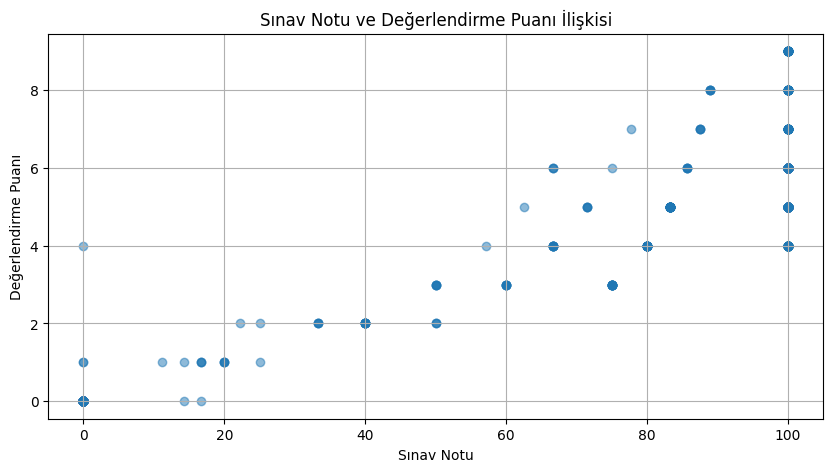

In [16]:
korelasyon = veri["Not"].corr(veri["Puan"])
print(f"Sınav notu ile değerlendirme puanı arasındaki Pearson korelasyonu: {korelasyon:.4f}")

if korelasyon > 0.7:
    yorum = "Güçlü pozitif ilişki"
elif korelasyon > 0.3:
    yorum = "Orta düzeyde pozitif ilişki"
elif korelasyon >= -0.3:
    yorum = "Zayıf ilişki"
elif korelasyon >= -0.7:
    yorum = "Orta düzeyde negatif ilişki"
else:
    yorum = "Güçlü negatif ilişki"

print("Yorum:", yorum)

plt.scatter(veri["Not"], veri["Puan"], alpha=0.5)
plt.title("Sınav Notu ve Değerlendirme Puanı İlişkisi")
plt.xlabel("Sınav Notu")
plt.ylabel("Değerlendirme Puanı")
plt.show()